## Carga del conjunto de datos
Carga el archivo `casas_10000.csv` desde la carpeta de datos.
Se utiliza pandas para leer el CSV y guardarlo en un DataFrame.


OBJETIVO DEL EJERCICIO: «Un árbol de decisión de fábrica, para estimar el precio de las casas, memoriza los
datos de entrenamiento. Ajustalo con una búsqueda aleatoria y después con
una búsqueda en cuadrícula, y decí cuánto mejoró.»

In [11]:
import pandas as pd

ruta_datos = "../data/raw/casas_10000.csv"
df_casas = pd.read_csv(ruta_datos)

df_casas.head()

,id,fecha_publicacion,barrio,latitud,longitud,distancia_centro_km,tipo,metros,habitaciones,banos,antiguedad,ascensor,terraza,garaje,precio,dias_en_venta
0,1,2019-01-01,Afueras,40.49816,-3.79204,11.71,piso,59,2,1,15,1,1,0,45000,33
1,2,2019-01-01,Afueras,40.48552,-3.78282,10.14,chalet,139,4,2,0,1,1,0,307000,63
2,3,2019-01-02,Centro,40.43006,-3.68737,2.02,piso,46,1,1,76,0,0,0,41000,20
3,4,2019-01-02,Centro,40.41869,-3.71814,1.23,piso,91,3,1,49,1,0,0,168000,33
4,5,2019-01-03,Afueras,40.50784,-3.79378,12.65,chalet,159,5,2,9,0,1,0,282000,23


## Selección de características y división de datos
Se definen las variables de entrada y el objetivo `precio`.
Se separan los datos en entrenamiento (80 %) y prueba (20 %).
Las variables categóricas `barrio` y `tipo` se codifican en columnas binarias.


In [12]:
from sklearn.model_selection import train_test_split

caracteristicas_numericas = [
    "metros",
    "habitaciones",
    "banos",
    "antiguedad",
    "distancia_centro_km",
    "ascensor",
    "terraza",
    "garaje",
]
caracteristicas_categoricas = ["barrio", "tipo"]
objetivo = "precio"

# Crear indicadores binarios (0/1) para barrio y tipo.
datos_modelo = pd.get_dummies(
    df_casas[caracteristicas_numericas + caracteristicas_categoricas + [objetivo]],
    columns=caracteristicas_categoricas,
    dtype=int,
)

X = datos_modelo.drop(columns=objetivo)
y = datos_modelo[objetivo]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Filas de entrenamiento: {len(X_train)}")
print(f"Filas de prueba: {len(X_test)}")
print(f"Características tras codificar barrio y tipo: {X.shape[1]}")

Filas de entrenamiento: 8000
Filas de prueba: 2000
Características tras codificar barrio y tipo: 18


## Línea base: árbol de decisión predeterminado
Se entrena un `DecisionTreeRegressor` con sus parámetros de fábrica.
Se calcula el error absoluto medio (MAE) en entrenamiento y prueba para establecer una referencia.


In [13]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

arbol_base = DecisionTreeRegressor()
arbol_base.fit(X_train, y_train)

predicciones_train_base = arbol_base.predict(X_train)
predicciones_test_base = arbol_base.predict(X_test)

mae_train_base = mean_absolute_error(y_train, predicciones_train_base)
mae_test_base = mean_absolute_error(y_test, predicciones_test_base)

print(f"MAE en entrenamiento: {mae_train_base:,.2f}")
print(f"MAE en prueba:        {mae_test_base:,.2f}")

MAE en entrenamiento: 0.00
MAE en prueba:        37,039.00


## Búsqueda aleatoria de hiperparámetros
Se prueban 20 combinaciones de profundidad y tamaños mínimos de hoja y división.
La validación cruzada de 5 partes usa únicamente el conjunto de entrenamiento.
Se optimiza el MAE; el conjunto de prueba queda reservado para la evaluación final.


In [14]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_leaf": randint(1, 11),
    "min_samples_split": randint(2, 21),
}

busqueda_aleatoria = RandomizedSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    refit=True,
)

# La búsqueda se ajusta solo con entrenamiento; X_test/y_test no participan en CV.
busqueda_aleatoria.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_aleatoria.best_params_)
print(f"MAE promedio de validación cruzada: {-busqueda_aleatoria.best_score_:,.2f}")

Mejores hiperparámetros: {'max_depth': 15, 'min_samples_leaf': 10, 'min_samples_split': 13}
MAE promedio de validación cruzada: 31,115.10


## Mejores 10 modelos de la búsqueda aleatoria
Se ordenan las 20 combinaciones probadas por su MAE de validación cruzada y se comparan con un árbol predeterminado evaluado con la misma validación cruzada. Un MAE menor indica mejor rendimiento. La prueba se mantiene reservada para la evaluación final.

,max_depth,min_samples_leaf,min_samples_split,MAE_CV,Desviacion_MAE_CV,MAE_base_CV,Desviacion_MAE_base_CV,Mejora_MAE,Mejora_%
Puesto,,,,,,,,,
1,15,10,13,31115.10,786.34,38593.12,1142.28,7478.02,19.38
2,15,9,4,31231.14,691.95,38593.12,1142.28,7361.99,19.08
3,20,9,8,31235.53,680.08,38593.12,1142.28,7357.60,19.06
4,10,8,5,31506.80,336.22,38593.12,1142.28,7086.33,18.36
5,20,8,16,31507.35,664.91,38593.12,1142.28,7085.78,18.36
6,15,8,8,31510.23,662.47,38593.12,1142.28,7082.89,18.35
7,10,6,3,31517.96,458.09,38593.12,1142.28,7075.17,18.33
8,15,7,13,31705.91,684.84,38593.12,1142.28,6887.22,17.85
9,15,6,3,31730.32,638.11,38593.12,1142.28,6862.80,17.78


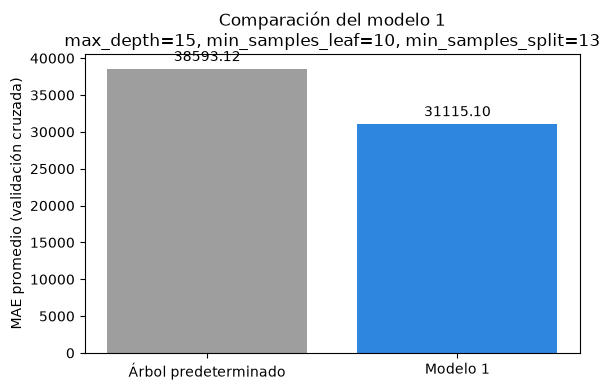

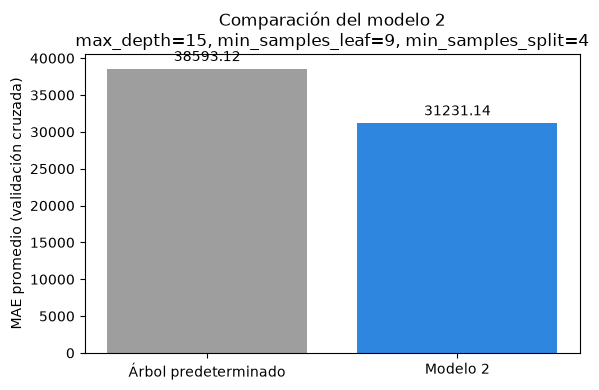

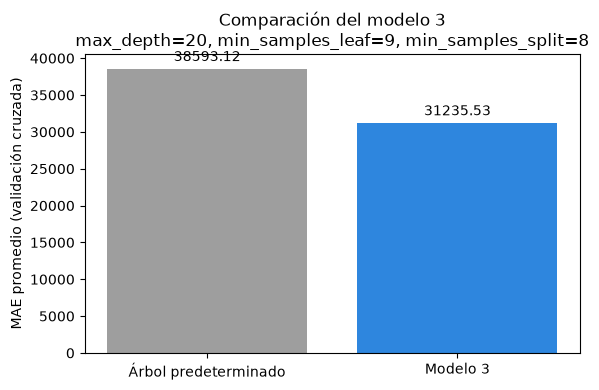

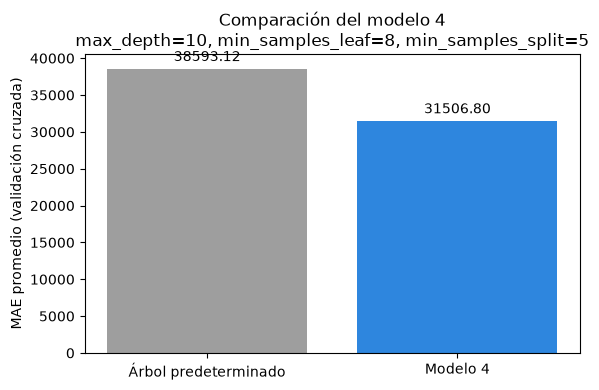

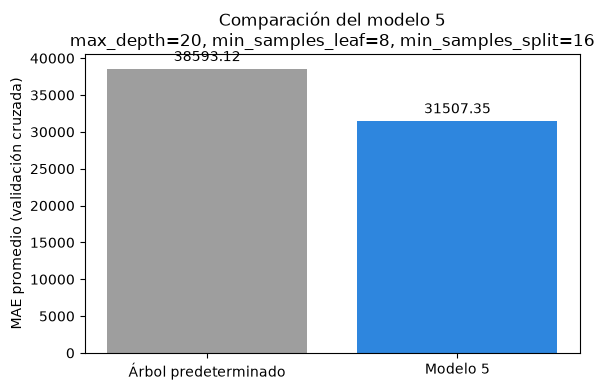

In [15]:
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

# Comparación justa: baseline y candidatos usan los mismos pliegues de CV
# y únicamente el conjunto de entrenamiento.
resultados_cv_base = cross_val_score(
    DecisionTreeRegressor(),
    X_train,
    y_train,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
)
mae_cv_base = -resultados_cv_base.mean()
desviacion_mae_cv_base = resultados_cv_base.std()

resultados_aleatorios = pd.DataFrame(busqueda_aleatoria.cv_results_)
resultados_aleatorios["MAE_CV"] = -resultados_aleatorios["mean_test_score"]
resultados_aleatorios["Desviacion_MAE_CV"] = resultados_aleatorios["std_test_score"]
resultados_aleatorios = resultados_aleatorios.sort_values("MAE_CV").head(10).copy()

# Mostrar solo los hiperparámetros solicitados y métricas frente al baseline.
resultados_aleatorios["MAE_base_CV"] = mae_cv_base
resultados_aleatorios["Desviacion_MAE_base_CV"] = desviacion_mae_cv_base
resultados_aleatorios["Mejora_MAE"] = mae_cv_base - resultados_aleatorios["MAE_CV"]
resultados_aleatorios["Mejora_%"] = (
    resultados_aleatorios["Mejora_MAE"] / mae_cv_base * 100
)

columnas_parametros = [
    "param_max_depth",
    "param_min_samples_leaf",
    "param_min_samples_split",
]
tabla_top10 = resultados_aleatorios[
    columnas_parametros + ["MAE_CV", "Desviacion_MAE_CV", "MAE_base_CV", "Desviacion_MAE_base_CV", "Mejora_MAE", "Mejora_%"]
].rename(columns={
    "param_max_depth": "max_depth",
    "param_min_samples_leaf": "min_samples_leaf",
    "param_min_samples_split": "min_samples_split",
})
tabla_top10.index = range(1, len(tabla_top10) + 1)
tabla_top10.index.name = "Puesto"
display(tabla_top10.round(2))

# Una gráfica por cada uno de los cinco mejores: MAE menor es mejor.
for puesto, (_, modelo) in enumerate(resultados_aleatorios.head(5).iterrows(), start=1):
    mae_modelo = modelo["MAE_CV"]
    parametros_modelo = (
        f"max_depth={modelo['param_max_depth']}, "
        f"min_samples_leaf={modelo['param_min_samples_leaf']}, "
        f"min_samples_split={modelo['param_min_samples_split']}"
    )

    plt.figure(figsize=(6, 4))
    barras = plt.bar(
        ["Árbol predeterminado", f"Modelo {puesto}"],
        [mae_cv_base, mae_modelo],
        color=["#9e9e9e", "#2e86de"],
    )
    plt.ylabel("MAE promedio (validación cruzada)")
    plt.title(f"Comparación del modelo {puesto}\n{parametros_modelo}")
    plt.bar_label(barras, fmt="%.2f", padding=3)
    plt.tight_layout()
    plt.show()

## Búsqueda en cuadrícula alrededor del mejor resultado
Se define una cuadrícula pequeña centrada en los mejores valores aleatorios.
Se conserva la validación cruzada de 5 partes y se usa solo el entrenamiento.
La selección sigue optimizando el MAE.


In [16]:
from sklearn.model_selection import GridSearchCV

mejores_aleatorios = busqueda_aleatoria.best_params_

# Construir valores cercanos al óptimo aleatorio, respetando los límites válidos.
def valores_cercanos(valor, incrementos, minimo):
    if valor is None:
        return [None, 20, 30]
    return sorted({max(minimo, valor + incremento) for incremento in incrementos})

cuadricula = {
    "max_depth": valores_cercanos(mejores_aleatorios["max_depth"], [-5, 0, 5], 1),
    "min_samples_leaf": valores_cercanos(mejores_aleatorios["min_samples_leaf"], [-2, 0, 2], 1),
    "min_samples_split": valores_cercanos(mejores_aleatorios["min_samples_split"], [-4, 0, 4], 2),
}

busqueda_cuadricula = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=cuadricula,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    refit=True,
)
busqueda_cuadricula.fit(X_train, y_train)

print("Cuadrícula evaluada:", cuadricula)
print("Mejores hiperparámetros refinados:", busqueda_cuadricula.best_params_)
print(f"MAE promedio de validación cruzada: {-busqueda_cuadricula.best_score_:,.2f}")

Cuadrícula evaluada: {'max_depth': [10, 15, 20], 'min_samples_leaf': [8, 10, 12], 'min_samples_split': [9, 13, 17]}
Mejores hiperparámetros refinados: {'max_depth': 20, 'min_samples_leaf': 12, 'min_samples_split': 9}
MAE promedio de validación cruzada: 30,886.29


## Visualización de la cuadrícula de hiperparámetros
El mapa de calor muestra el MAE medio de validación cruzada para cada combinación de `max_depth` y `min_samples_leaf`. Se crea un panel por cada valor de `min_samples_split`. Los valores más bajos de MAE indican mejor rendimiento.

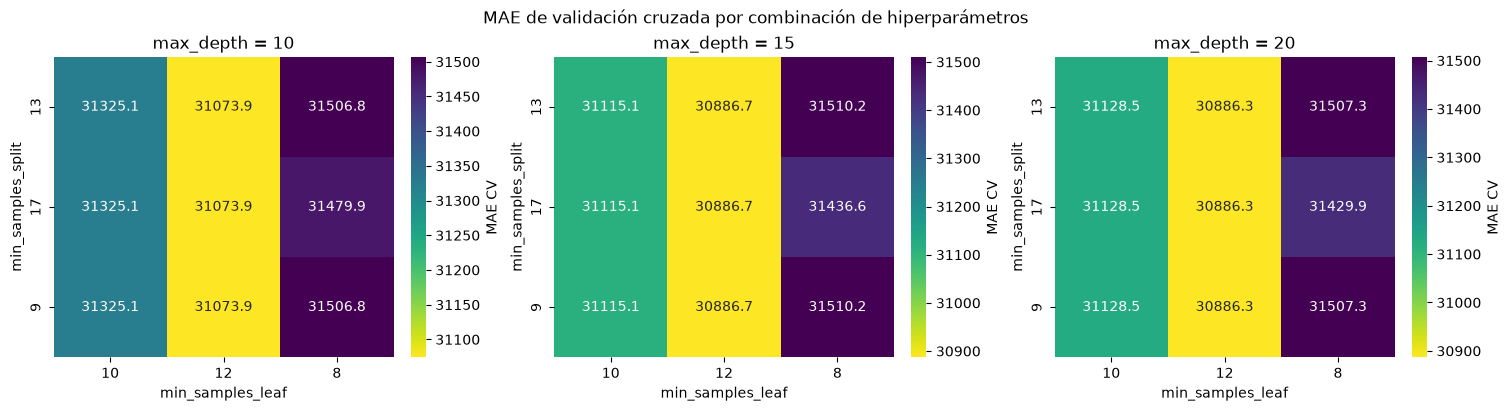

Mejor combinación: {'max_depth': 20, 'min_samples_leaf': 12, 'min_samples_split': 9}
Mejor MAE medio CV: 30,886.29


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extraer las combinaciones probadas por GridSearchCV y su MAE de CV.
resultados_grid_viz = pd.DataFrame(busqueda_cuadricula.cv_results_).copy()
resultados_grid_viz["MAE_CV"] = -resultados_grid_viz["mean_test_score"]

# Convertir valores categóricos/None para una visualización clara.
resultados_grid_viz["max_depth_label"] = resultados_grid_viz["param_max_depth"].map(
    lambda valor: "Sin límite" if pd.isna(valor) else str(valor)
)
resultados_grid_viz["min_samples_leaf_label"] = resultados_grid_viz[
    "param_min_samples_leaf"
].astype(str)
resultados_grid_viz["min_samples_split_label"] = resultados_grid_viz[
    "param_min_samples_split"
].astype(str)

profundidades = resultados_grid_viz["max_depth_label"].drop_duplicates().tolist()
fig, ejes = plt.subplots(
    1,
    len(profundidades),
    figsize=(5 * len(profundidades), 4),
    squeeze=False,
    constrained_layout=True,
)

for eje, profundidad in zip(ejes[0], profundidades):
    datos_profundidad = resultados_grid_viz[
        resultados_grid_viz["max_depth_label"] == profundidad
    ]
    matriz = datos_profundidad.pivot_table(
        index="min_samples_split_label",
        columns="min_samples_leaf_label",
        values="MAE_CV",
        aggfunc="mean",
    )
    sns.heatmap(
        matriz,
        annot=True,
        fmt=".1f",
        cmap="viridis_r",
        ax=eje,
        cbar_kws={"label": "MAE CV"},
    )
    eje.set_title(f"max_depth = {profundidad}")
    eje.set_xlabel("min_samples_leaf")
    eje.set_ylabel("min_samples_split")

fig.suptitle("MAE de validación cruzada por combinación de hiperparámetros")
plt.show()

print("Mejor combinación:", busqueda_cuadricula.best_params_)
print(f"Mejor MAE medio CV: {-busqueda_cuadricula.best_score_:,.2f}")

## Interpretación de los resultados
Se ordenan los resultados de validación cruzada para comparar las combinaciones probadas.
Se resume qué hiperparámetro influye más en el MAE y cuál parece no cambiarlo.
La conclusión es orientativa: depende de los valores explorados y de los datos.


In [18]:
# Comparar el MAE medio de CV según cada hiperparámetro.
resultados_grid = pd.DataFrame(busqueda_cuadricula.cv_results_)
resultados_grid["MAE_CV"] = -resultados_grid["mean_test_score"]

parametros = ["max_depth", "min_samples_leaf", "min_samples_split"]
resumen_parametros = {}

for parametro in parametros:
    columna = f"param_{parametro}"
    resumen = (
        resultados_grid.groupby(columna, dropna=False)["MAE_CV"]
        .agg(["mean", "min", "max", "count"])
        .sort_values("mean")
    )
    resumen_parametros[parametro] = resumen
    print(f"\\nMAE de validación cruzada por {parametro}:")
    display(resumen)

# Medir el rango de los MAE promedio agrupados: mayor rango implica mayor
# diferencia observada entre sus valores probados.
rangos_mae = {
    parametro: tabla["mean"].max() - tabla["mean"].min()
    for parametro, tabla in resumen_parametros.items()
}
hiperparametro_mas_influyente = max(rangos_mae, key=rangos_mae.get)
hiperparametro_menor_cambio = min(rangos_mae, key=rangos_mae.get)

print("Rango de MAE agrupado por hiperparámetro:", rangos_mae)
print(f"Mayor cambio observado: {hiperparametro_mas_influyente}")
print(f"Menor cambio observado: {hiperparametro_menor_cambio}")
print("La menor variación no implica necesariamente que el hiperparámetro sea irrelevante fuera de esta cuadrícula.")

\nMAE de validación cruzada por max_depth:


,mean,min,max,count
param_max_depth,,,,
15,31162.486053,30886.672275,31510.232670,9
20,31165.459877,30886.291936,31507.346096,9
10,31298.931232,31073.900452,31506.797478,9


\nMAE de validación cruzada por min_samples_leaf:


,mean,min,max,count
param_min_samples_leaf,,,,
12,30948.954888,30886.291936,31073.900452,9
10,31189.574140,31115.103382,31325.070991,9
8,31488.348133,31429.926749,31510.232670,9


\nMAE de validación cruzada por min_samples_split:


,mean,min,max,count
param_min_samples_split,,,,
17,31195.774199,30886.291936,31479.871797,9
9,31215.551481,30886.291936,31510.232670,9
13,31215.551481,30886.291936,31510.232670,9


Rango de MAE agrupado por hiperparámetro: {'max_depth': np.float64(136.44517902523512), 'min_samples_leaf': np.float64(539.39324552381), 'min_samples_split': np.float64(19.777281765302178)}
Mayor cambio observado: min_samples_leaf
Menor cambio observado: min_samples_split
La menor variación no implica necesariamente que el hiperparámetro sea irrelevante fuera de esta cuadrícula.


## Evaluación final y resumen solicitado
Se compara el árbol de fábrica con el mejor árbol ajustado, usando la prueba una sola vez.
Se presenta una tabla con las mejores combinaciones y sus MAE de validación cruzada y de prueba.
Al final se resumen el hiperparámetro más influyente y la mejora porcentual del MAE.


In [19]:
# El estimador final de la cuadrícula ya fue reajustado solo con X_train/y_train.
arbol_ajustado = busqueda_cuadricula.best_estimator_
predicciones_test_ajustado = arbol_ajustado.predict(X_test)
mae_test_ajustado = mean_absolute_error(y_test, predicciones_test_ajustado)

# Resumen de los ganadores de ambas búsquedas; std_test_score representa la
# desviación estándar de los MAE de los pliegues de validación cruzada.
resultados_aleatorios_completos = pd.DataFrame(busqueda_aleatoria.cv_results_)
resultados_grid_completos = pd.DataFrame(busqueda_cuadricula.cv_results_)
mejores_combinaciones = pd.DataFrame([
    {
        "búsqueda": "Aleatoria",
        **busqueda_aleatoria.best_params_,
        "MAE_CV": -busqueda_aleatoria.best_score_,
        "Desviacion_MAE_CV": resultados_aleatorios_completos.loc[
            busqueda_aleatoria.best_index_, "std_test_score"
        ],
    },
    {
        "búsqueda": "Cuadrícula",
        **busqueda_cuadricula.best_params_,
        "MAE_CV": -busqueda_cuadricula.best_score_,
        "Desviacion_MAE_CV": resultados_grid_completos.loc[
            busqueda_cuadricula.best_index_, "std_test_score"
        ],
    },
]).set_index("búsqueda")

display(mejores_combinaciones.round(2))

comparacion_mae = pd.DataFrame(
    {
        "modelo": ["Árbol de fábrica", "Árbol ajustado"],
        "MAE_prueba": [mae_test_base, mae_test_ajustado],
        "Desviacion_MAE_CV": [desviacion_mae_cv_base, resultados_grid_completos.loc[
            busqueda_cuadricula.best_index_, "std_test_score"
        ]],
    }
).set_index("modelo")
display(comparacion_mae.round(2))

mejora_absoluta = mae_test_base - mae_test_ajustado
mejora_porcentual = (mejora_absoluta / mae_test_base * 100) if mae_test_base else float("nan")
print(
    f"El hiperparámetro con mayor cambio observado en la cuadrícula fue "
    f"{hiperparametro_mas_influyente}; el de menor cambio fue "
    f"{hiperparametro_menor_cambio}."
)
print(
    f"El MAE de prueba cambió de {mae_test_base:,.2f} a "
    f"{mae_test_ajustado:,.2f}: mejora de {mejora_absoluta:,.2f} "
    f"({mejora_porcentual:.2f} %; un valor negativo indica empeoramiento)."
)

,max_depth,min_samples_leaf,min_samples_split,MAE_CV,Desviacion_MAE_CV
búsqueda,,,,,
Aleatoria,15,10,13,31115.10,786.34
Cuadrícula,20,12,9,30886.29,987.20


,MAE_prueba,Desviacion_MAE_CV
modelo,,
Árbol de fábrica,37039.00,1142.28
Árbol ajustado,28780.87,987.20


El hiperparámetro con mayor cambio observado en la cuadrícula fue min_samples_leaf; el de menor cambio fue min_samples_split.
El MAE de prueba cambió de 37,039.00 a 28,780.87: mejora de 8,258.13 (22.30 %; un valor negativo indica empeoramiento).
